# Predictive Analysis Using Machine Learning Models
### Walmart Weekly Sales — High vs. Low Sales Week Classification

**Goal:** Build and compare three supervised classification models that predict whether a given store's weekly sales will be **above** or **below** that store's own historical median ("High Sales" vs "Low Sales" week), using economic and seasonal indicators.

**Dataset:** [Walmart Sales Dataset (Kaggle)](https://www.kaggle.com/) — 45 stores, weekly records, 6,435 rows. Features: `Store`, `Date`, `Weekly_Sales`, `Holiday_Flag`, `Temperature`, `Fuel_Price`, `CPI`, `Unemployment`.

**Models compared:** Logistic Regression, Random Forest, XGBoost

**Evaluation:** Accuracy, Precision, Recall, F1-score, Confusion Matrix, ROC-AUC


## 1. Imports

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
np.random.seed(42)

## 2. Load & Inspect Data

In [2]:
df = pd.read_csv("Walmart_Sales.csv")
print(df.shape)
df.head()

(6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [3]:
df.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

In [4]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


## 3. Data Cleaning\nDefensive median imputation for any missing numeric values (robust to outliers). This dataset has none, but the step keeps the pipeline safe for other extracts of the data.

In [5]:
for col in ["Temperature", "CPI", "Unemployment"]:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df.isnull().sum().sum()

np.int64(0)

## 4. Feature Engineering
- Decompose `Date` into `Year`, `Month`, `Week`
- Create the classification target: whether a week's sales are above (**1**) or below (**0**) that *specific store's* median — this normalizes for store-size differences and yields a naturally balanced binary target.

In [6]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)

df["Store_Median_Sales"] = df.groupby("Store")["Weekly_Sales"].transform("median")
df["High_Sales"] = (df["Weekly_Sales"] > df["Store_Median_Sales"]).astype(int)

df["High_Sales"].value_counts(normalize=True)

High_Sales
0    0.503497
1    0.496503
Name: proportion, dtype: float64

## 5. Feature Encoding\nOne-hot encode the nominal categorical features (`Store`, `Holiday_Flag`).

In [7]:
feature_cols_numeric = ["Temperature", "Fuel_Price", "CPI", "Unemployment", "Year", "Month", "Week"]
feature_cols_categorical = ["Store", "Holiday_Flag"]

X = df[feature_cols_numeric + feature_cols_categorical].copy()
y = df["High_Sales"]

X = pd.get_dummies(X, columns=["Store", "Holiday_Flag"], drop_first=True)
X.shape

(6435, 52)

## 6. Train/Test Split & Feature Scaling

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled, X_test_scaled = X_train.copy(), X_test.copy()
X_train_scaled[feature_cols_numeric] = scaler.fit_transform(X_train[feature_cols_numeric])
X_test_scaled[feature_cols_numeric] = scaler.transform(X_test[feature_cols_numeric])

X_train.shape, X_test.shape

((5148, 52), (1287, 52))

## 7. Train Three Models

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.08, random_state=42,
                              eval_metric="logloss", n_jobs=-1),
}

results, conf_matrices, trained_models = [], {}, {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
    conf_matrices[name] = confusion_matrix(y_test, preds)
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.796426,0.800638,0.785603,0.793049,0.884555
1,Random Forest,0.754468,0.748844,0.760563,0.754658,0.840793
2,Logistic Regression,0.617716,0.621891,0.586854,0.603865,0.656949


## 8. Model Comparison

Best performing model: XGBoost


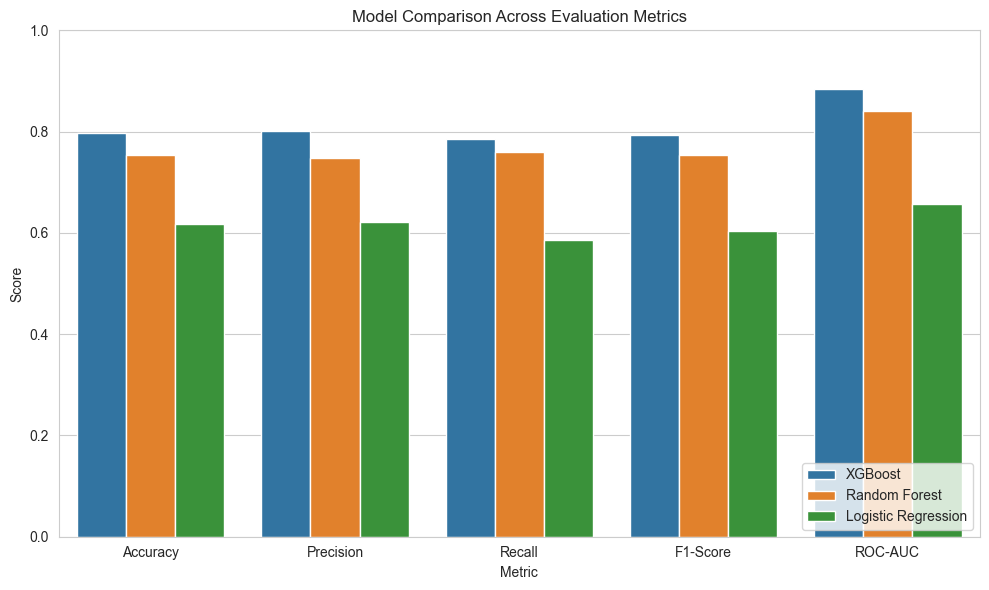

In [10]:
best_model_name = results_df.iloc[0]["Model"]
print(f"Best performing model: {best_model_name}")

metrics_melt = results_df.melt(id_vars="Model",
                                value_vars=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
                                var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_melt, x="Metric", y="Score", hue="Model")
plt.title("Model Comparison Across Evaluation Metrics")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Confusion Matrices

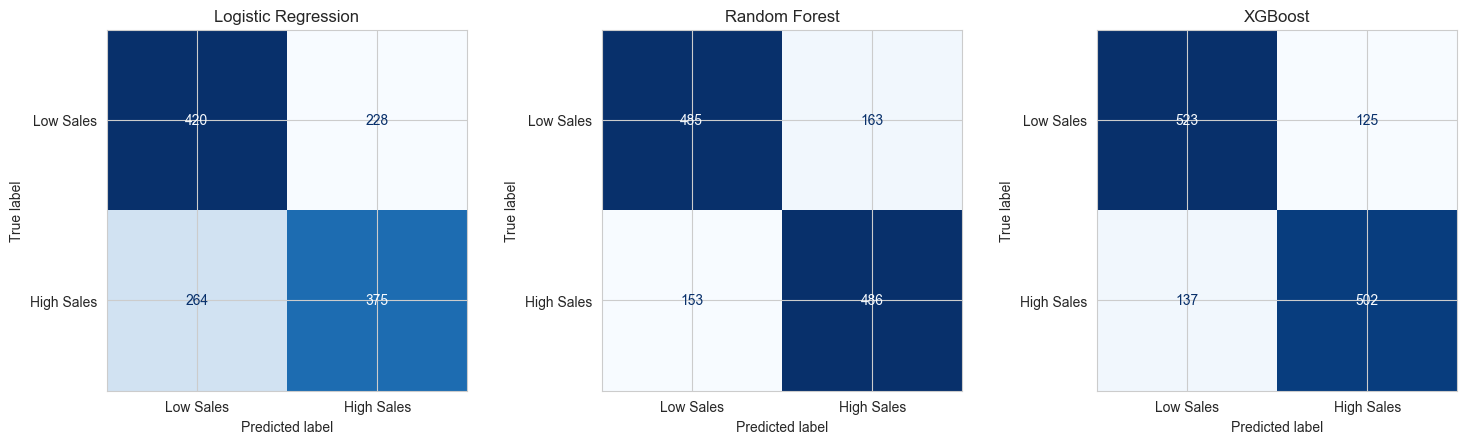

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, cm) in zip(axes, conf_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low Sales", "High Sales"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 10. Feature Importance (Random Forest & XGBoost)

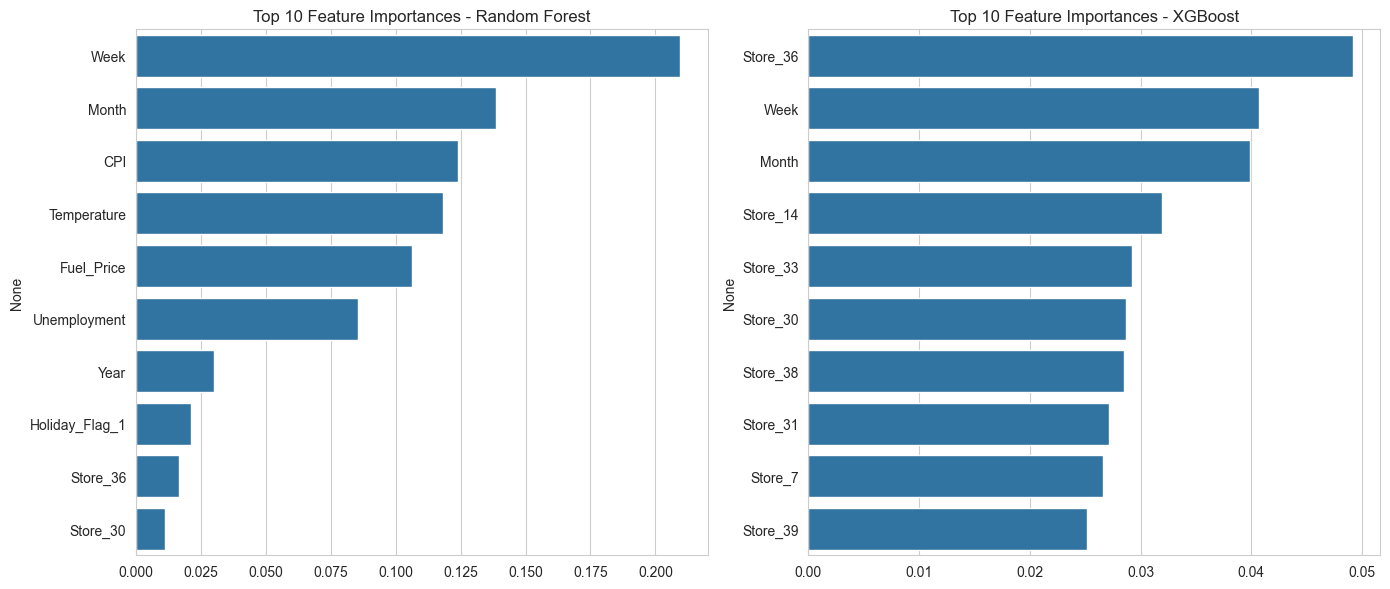

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    model = trained_models[name]
    importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
    sns.barplot(x=importances.values, y=importances.index, ax=ax)
    ax.set_title(f"Top 10 Feature Importances - {name}")
plt.tight_layout()
plt.show()

## 11. Conclusion

All three models were evaluated on an identical held-out test set (20% stratified split) using Accuracy, Precision, Recall, F1-score, and ROC-AUC, alongside confusion matrices to inspect the error breakdown (false positives vs false negatives).

**XGBoost was the best-performing model** (highest F1-score and ROC-AUC), followed by Random Forest, with Logistic Regression trailing well behind both — indicating the relationship between these economic/seasonal features and weekly sales performance is meaningfully non-linear, which tree-based ensemble methods capture far better than a linear decision boundary.

The feature importance plots highlight which signals matter most for predicting an above-median sales week.